<img src="../../branding/aa-wordmark.png" alt="AA Engineering Toolkit" width="320px">

*Areeb Ahmed | Mechanical Engineer*

# Pipe Sizing

- Using Darcy Weisbach Formula
- ASME B31.3 (Process Piping) and B31.1 (Power piping)
- Major and Minor losses
- Velocity recommended for liquids 0- 5m/s
- Velocity recomeded for saturated steam 15-30 m/s
- Superheated steam 30-50 m/s
- Gases with high condensing points 50-80 m/s

In [1]:
import numpy as np
from engtoolkit.catalogs import crane_le_over_d
from engtoolkit.core.plotting import use_style
from engtoolkit.core.units import bar_to_pa, c_to_k
from engtoolkit.materials import fluid, get_material
from engtoolkit.thermo import CraneMinorLoss, Pipe, PipeElement, PipeFlow, PipeLine, PipeSizer

use_style()
crane_data = crane_le_over_d()  # Crane TP-410 L/D values

fluid_name = "Water"  # directly from CoolProp
T = c_to_k(180)            # K
P = bar_to_pa(5)           # Pa
pipe_length = 50.0         # m
mass_flowrate = 3600       # kg/hr
density = fluid(fluid_name).state(T=T, P=P).rho
Q = mass_flowrate / density / 3600     # m³/s (desired volumetric flow)
material = get_material("ASTM A106B")
n_elbow = 3
n_valve = 3
n_tee_straight = 5
n_tee_branch = 4

v_max = 30  # m/s

sizer = PipeSizer(fluid_name=fluid_name, material=material, T=T, P=P, length=pipe_length)

D_suggested = sizer.size_for_max_velocity(Q, v_max)
print(f"Suggested pipe diameter based on max velocity: {D_suggested:.3f} m")

# Pipe and PipeFlow objects
pipe = Pipe(diameter=D_suggested, length=pipe_length, material=material)
flow = PipeFlow(pipe, fluid_name=fluid_name, T=T, P=P)  # CoolProp fluid

# Pipeline: major loss (friction) + minor losses (Crane K = f_T * L/D)
line = PipeLine()
line.add(PipeElement(flow))
line.add(CraneMinorLoss("elbow_90_standard", flow, crane_data, count=4))
line.add(CraneMinorLoss("tee_straight", flow, crane_data, count=2))
line.add(CraneMinorLoss("tee_branch", flow, crane_data, count=1))

dp_total = line.total_pressure_drop(Q)
print(f"Total pressure drop including fittings: {dp_total/1000:.2f} kPa")

Re = flow.reynolds(Q)
print(f"Reynolds number at Q={Q:.3f} m³/s: {Re:.0f}")

Suggested pipe diameter based on max velocity: 0.131 m
Total pressure drop including fittings: 10.71 kPa
Reynolds number at Q=0.405 m³/s: 638515


You may calculate the pressure drop for different pipe sizes and the corresponding velocities and see if they fall within the recommended ranges. It also outputs the projected cost of the pipeline in terms of raw materials. There is a function built for this.

All costs are based on kenyan suppliers but using USD assuming each pipe is 5.8m.

Costs come from `engtoolkit/catalogs/data/pipe_costs.csv` (pipe only; fittings and valves are in the catalog for later use).

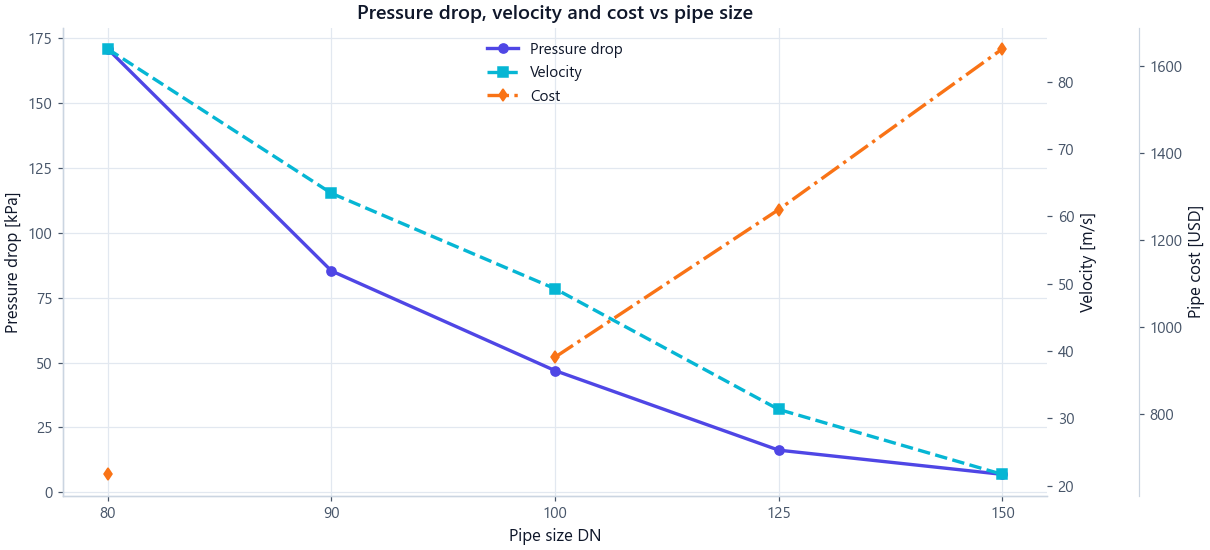

In [2]:
from engtoolkit.thermo import pipe_size_sweep
from engtoolkit.thermo.plots import pipe_size_sweep_plot

fittings = {"elbow_90_standard": n_elbow, "tee_straight": n_tee_straight,
            "gate_valve_open": n_valve, "tee_branch": n_tee_branch}

rows = pipe_size_sweep(fluid_name, T, P, pipe_length, mass_flow=mass_flowrate / 3600,
                       dn_range=(80, 150), fittings=fittings)
pipe_size_sweep_plot(rows)

## Insulation of Pipes
Assumption
- Ambient remains constant
- Temperature of pipe inner wall is the temperature of the fluid

Mineral wool thickness for 50 W/m: 74 mm (surface 32.0 °C, bare pipe 1028 W/m)


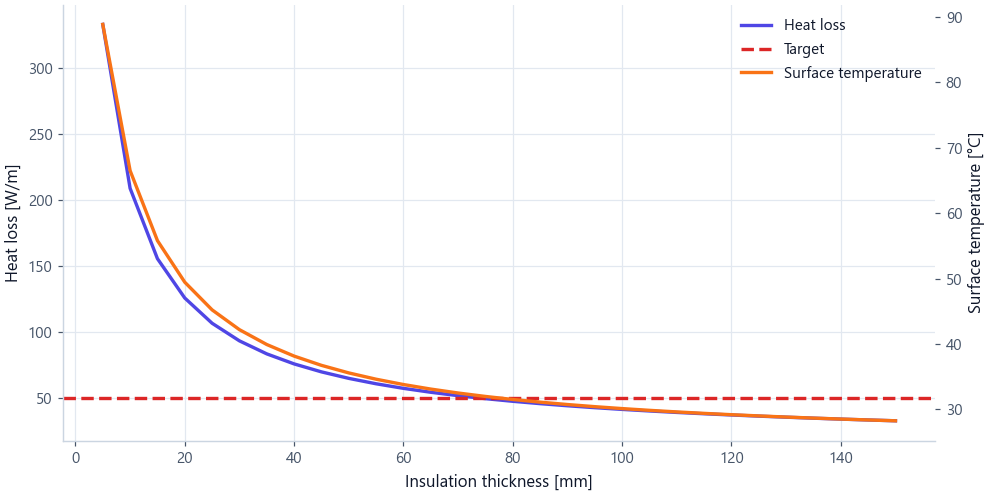

In [3]:
from engtoolkit.catalogs import pipe as pipe_size
from engtoolkit.thermo import heat_loss_vs_thickness, insulation_thickness
from engtoolkit.thermo.plots import insulation_plot

dn100 = pipe_size(100)
target = 50  # W/m
sized = insulation_thickness(dn100.id, dn100.od, T_fluid=T, T_ambient=c_to_k(25), q_max=target,
                             k_insulation="Mineral wool")
print(f"Mineral wool thickness for {target} W/m: {sized.thickness * 1000:.0f} mm "
      f"(surface {sized.T_surface - 273.15:.1f} °C, bare pipe {sized.bare_heat_loss:.0f} W/m)")

sweep = heat_loss_vs_thickness(dn100.id, dn100.od, T, c_to_k(25), "Mineral wool", np.linspace(0.005, 0.15, 30))
insulation_plot(sweep, q_target=target)